# 📘 Practical Linear Algebra for Data Science

## 🔹 1. Introduction

Linear Algebra is a cornerstone of data science, machine learning, and artificial intelligence. 

It underpins many key algorithms including Principal Component Analysis (PCA), Singular Value Decomposition (SVD), and Linear Regression. 

In this notebook, we will explore core concepts of linear algebra, demonstrate them using Python, and provide exercises to reinforce learning.




In [7]:
%pip install sklearn


  Using cached sklearn-0.0.post12.tar.gz (2.6 kB)
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'error'
Note: you may need to restart the kernel to use updated packages.


  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> [15 lines of output]
      The 'sklearn' PyPI package is deprecated, use 'scikit-learn'
      rather than 'sklearn' for pip commands.
      
      Here is how to fix this error in the main use cases:
      - use 'pip install scikit-learn' rather than 'pip install sklearn'
      - replace 'sklearn' by 'scikit-learn' in your pip requirements files
        (requirements.txt, setup.py, setup.cfg, Pipfile, etc ...)
      - if the 'sklearn' package is used by one of your dependencies,
        it would be great if you take some time to track which package uses
        'sklearn' instead of 'scikit-learn' and report it to their issue tracker
      - as a last resort, set the environment variable
        SKLEARN_ALLOW_DEPRECATED_SKLEARN_PACKAGE_INSTALL=True to avoid this error
      
      More information is available at
      https://github.com/scikit-learn/sklearn-

In [10]:
%pip install scikit-learn

   ---------------------------------------- 0.0/11.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.1 MB ? eta -:--:--
    --------------------------------------- 0.3/11.1 MB ? eta -:--:--
   -- ------------------------------------- 0.8/11.1 MB 1.7 MB/s eta 0:00:07
   --- ------------------------------------ 1.0/11.1 MB 1.8 MB/s eta 0:00:06
   ----- ---------------------------------- 1.6/11.1 MB 1.7 MB/s eta 0:00:06
   ------ --------------------------------- 1.8/11.1 MB 1.8 MB/s eta 0:00:06
   -------- ------------------------------- 2.4/11.1 MB 1.9 MB/s eta 0:00:05
   ----------- ---------------------------- 3.1/11.1 MB 2.0 MB/s eta 0:00:04
   ------------- -------------------------- 3.7/11.1 MB 2.1 MB/s eta 0:00:04
   --------------- ------------------------ 4.2/11.1 MB 2.1 MB/s eta 0:00:04
   ---------------- ----------------------- 4.7/11.1 MB 2.2 MB/s eta 0:00:03
   -------------------- ------------------- 5.8/11.1 MB 2.4 MB/s eta 0:00:03
   -----------------


[notice] A new release of pip is available: 25.0.1 -> 25.1.1
[notice] To update, run: C:\Users\ashok\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [11]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.linalg import norm, inv, det, matrix_rank, eig, svd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import load_iris

# Set plotting style
plt.style.use('seaborn')

OSError: 'seaborn' is not a valid package style, path of style file, URL of style file, or library style name (library styles are listed in `style.available`)

---

## 🔹 2. Vectors
### 📖 Concept
A vector is an ordered collection of numbers, often representing a point or direction in space. 
In data science, vectors often represent features or observations.

### 🧪 Operations
- Addition
- Scalar multiplication
- Dot product
- Magnitude
- Angle between vectors

### 🧪 Code Demonstration

In [12]:

v1 = np.array([2, 3])
v2 = np.array([1, 4])

add = v1 + v2
scalar_mul = 3 * v1
dot_product = np.dot(v1, v2)
magnitude_v1 = norm(v1)
angle_rad = np.arccos(dot_product / (norm(v1) * norm(v2)))
angle_deg = np.degrees(angle_rad)

print("v1 + v2 =", add)
print("3 * v1 =", scalar_mul)
print("Dot product =", dot_product)
print("Magnitude of v1 =", magnitude_v1)
print("Angle between v1 and v2 (degrees) =", angle_deg)


v1 + v2 = [3 7]
3 * v1 = [6 9]
Dot product = 14
Magnitude of v1 = 3.605551275463989
Angle between v1 and v2 (degrees) = 19.653824058053292


---

### ✅ Exercise
1. Create two 3D vectors, e.g., `v1 = np.array([1, 2, 3])` and `v2 = np.array([4, -5, 6])`. Compute their dot product and the angle between them in degrees.
2. Normalize a given vector, such as `v = np.array([4, 0, 3])`, to a unit vector using the formula `v_normalized = v / norm(v)`.

---

<details>
<summary>🔍 Click here to reveal the solution</summary>

```python

# 1. Dot product and angle
v1 = np.array([1, 2, 3])
v2 = np.array([4, -5, 6])
dot_product = np.dot(v1, v2)
angle_rad = np.arccos(dot_product / (norm(v1) * norm(v2)))
angle_deg = np.degrees(angle_rad)
print("Dot Product:", dot_product)
print("Angle (degrees):", angle_deg)

# 2. Normalize
v = np.array([4, 0, 3])
v_normalized = v / norm(v)
print("Normalized vector:", v_normalized)

```

---

## 🔹 3. Matrices
### 📖 Concept
A matrix is a rectangular array of numbers. Matrices are fundamental for representing and transforming data.

### 🧪 Properties & Operations
- Shape and dimension
- Transpose
- Matrix multiplication
- Identity and zero matrices

### 🧪 Code Demonstration

In [13]:
A = np.array([[1, 2], [3, 4]])
B = np.array([[2, 0], [1, 2]])

print("Shape of A:", A.shape)
print("Transpose of A:\n", A.T)
print("Matrix multiplication A @ B:\n", A @ B)

Shape of A: (2, 2)
Transpose of A:
 [[1 3]
 [2 4]]
Matrix multiplication A @ B:
 [[ 4  4]
 [10  8]]


---

### ✅ Exercise
1. Create a 3x3 matrix using `np.array()` and print its transpose using `.T`.
2. Multiply two 2x2 matrices, `M1 = np.array([[2, 1], [0, 3]])` and `M2 = np.array([[1, 2], [4, 5]])`. Print and verify the result manually by computing each element.

---

<details>
<summary>🔍 Click here to reveal the solution</summary>

```python
# 1. Transpose
M = np.array([[1, 2, 3], [4, 5, 6], [7, 8, 9]])
print("Transpose:\n", M.T)

# 2. Matrix multiplication
M1 = np.array([[2, 1], [0, 3]])
M2 = np.array([[1, 2], [4, 5]])
product = M1 @ M2
print("M1 x M2 =\n", product)
```

---


## 🔹 4. Linear Combinations and Span

### 📖 Concept

* **Linear Combination**: A linear combination of vectors $\{v_1, v_2, \dots, v_n\}$ is an expression of the form:

  $$
  c_1 v_1 + c_2 v_2 + \cdots + c_n v_n
  $$

  where $c_1, c_2, \dots, c_n$ are scalars (also called coefficients).

* **Span**: The **span** of a set of vectors $\{v_1, v_2, \dots, v_n\}$ is the set of all possible linear combinations of these vectors. The span represents all the points you can reach using those vectors in the vector space.

  * The span of a single vector is the line through the origin in its direction.
  * The span of two vectors is a plane (if they are not parallel) in 2D or 3D space.
  * The span of multiple vectors defines a subspace in higher dimensions.

---

### 🧠 Interpretation

* **Linear Combinations** describe how vectors can combine to form new vectors.

* **Span** tells you how far your set of vectors can "reach" or how much of the vector space they can cover.

* If the span of vectors covers the entire space (e.g., the span of two independent vectors covers the entire plane in $\mathbb{R}^2$), then the vectors **span the space**.

---


### 🧪 Code Demonstration

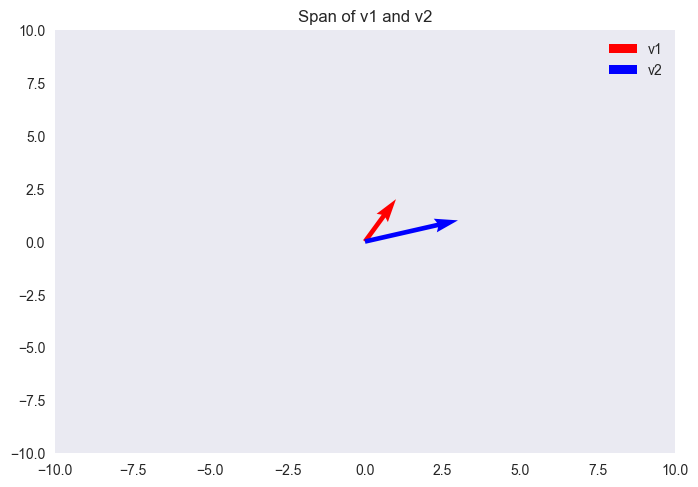

In [17]:
v1 = np.array([1, 2])
v2 = np.array([3, 1])

# Plot span
plt.quiver(0, 0, v1[0], v1[1], color='r', angles='xy', scale_units='xy', scale=1, label='v1')
plt.quiver(0, 0, v2[0], v2[1], color='b', angles='xy', scale_units='xy', scale=1, label='v2')
plt.xlim(-10, 10)
plt.ylim(-10, 10)
plt.grid()
plt.legend()
plt.title("Span of v1 and v2")
plt.show()

---

### ✅ Exercise
1. Define `v1 = np.array([2, 4])` and `v2 = np.array([1, 2])`. Plot both vectors and observe what happens to their span when one is a scalar multiple of the other.
2. Try vectors `a = np.array([1, 0])`, `b = np.array([0, 1])`, and `c = np.array([1, 1])`. Plot their combinations to verify whether they span ℝ².

---

<details>
<summary>🔍 Click here to reveal the solution</summary>

```python
# 1. Colinear vectors (same span)
v1 = np.array([2, 4])
v2 = np.array([1, 2])
plt.quiver(0, 0, v1[0], v1[1], angles='xy', scale_units='xy', scale=1, color='r', label='v1')
plt.quiver(0, 0, v2[0], v2[1], angles='xy', scale_units='xy', scale=1, color='b', label='v2')
plt.legend(); plt.grid(); plt.xlim(-5, 5); plt.ylim(-5, 5); plt.title("Colinear Vectors")
plt.show()

# 2. Span of R2
a = np.array([1, 0])
b = np.array([0, 1])
c = np.array([1, 1])
plt.quiver(0, 0, a[0], a[1], color='r', label='a')
plt.quiver(0, 0, b[0], b[1], color='g', label='b')
plt.quiver(0, 0, c[0], c[1], color='b', label='c')
plt.legend(); plt.grid(); plt.xlim(-2, 2); plt.ylim(-2, 2)
plt.title("Span of R2")
plt.show()
```


---


## 🔹 5. Linear Independence

### 📖 Concept

A set of vectors $\{v_1, v_2, \dots, v_n\}$ is **linearly independent** if **no vector in the set** can be written as a linear combination of the others.

Formally, the set is linearly independent if the only solution to:

$$
c_1 v_1 + c_2 v_2 + \cdots + c_n v_n = 0
$$

is:

$$
c_1 = c_2 = \cdots = c_n = 0
$$

Otherwise, the set is **linearly dependent**.

---

### 🧮 Key Properties

* **Fewer vectors than dimensions** (e.g., 2 vectors in $\mathbb{R}^3$) are often linearly independent.
* If at least one vector is a combination of the others, the set is dependent.
* A **square matrix** is invertible **iff** its column vectors are linearly independent.

---

### 🧠 Interpretation

* Linearly independent vectors **span** a space **without redundancy**.
* Linear dependence means **some vectors don't add new directions** — they lie in the span of others.

---

### 💻 Python Example

```python
import numpy as np

# Set of vectors
v1 = np.array([1, 2, 3])
v2 = np.array([4, 5, 6])
v3 = np.array([7, 8, 9])

# Stack as matrix
A = np.column_stack([v1, v2, v3])

# Check rank
rank = np.linalg.matrix_rank(A)
print("Rank:", rank)

if rank == A.shape[1]:
    print("Vectors are linearly independent")
else:
    print("Vectors are linearly dependent")
```

---


### 🧪 Code Demonstration

In [18]:
C = np.array([[1, 2], [2, 4]])
rank_C = matrix_rank(C)
print("Rank of C =", rank_C)

Rank of C = 1



---

### ✅ Exercise
1. Define three vectors: `a = np.array([1, 2, 3])`, `b = np.array([0, 1, 4])`, and `c = np.array([1, 3, 7])`. Stack them into a matrix and use `matrix_rank()` to check for independence.

---

<details>
<summary>🔍 Click here to reveal the solution</summary>

```python
a = np.array([1, 2, 3])
b = np.array([0, 1, 4])
c = np.array([1, 3, 7])
M = np.stack([a, b, c], axis=1)
print("Matrix Rank:", matrix_rank(M))  # If rank < 3, vectors are dependent
```

---

## 🔹 6. Matrix Inverse and Determinant

### 📖 Concept

* The **inverse** of a square matrix $A$ is a matrix $A^{-1}$ such that:

  $$
  A \cdot A^{-1} = A^{-1} \cdot A = I
  $$

  where $I$ is the identity matrix.
* The **determinant** $\text{det}(A)$ is a scalar value that provides important properties of the matrix:

  * $\text{det}(A) \neq 0$ ⟹ matrix is **invertible**.
  * $\text{det}(A) = 0$ ⟹ matrix is **singular** (not invertible).

---

### 🧮 Key Properties

* Only **square matrices** have a determinant and potentially an inverse.
* For a $2 \times 2$ matrix:

  $$
  A = \begin{bmatrix}
  a & b \\
  c & d
  \end{bmatrix}, \quad
  A^{-1} = \frac{1}{ad - bc}
  \begin{bmatrix}
  d & -b \\
  -c & a
  \end{bmatrix}
  $$
* For larger matrices, use methods like:

  * **Gaussian elimination**
  * **LU decomposition**
  * **Adjoint method**

---

### 🧠 Interpretations

* A matrix with $\text{det}(A) = 0$ is **not full-rank** (its columns are linearly dependent).
* The determinant can also be interpreted as the **volume scaling factor** of the linear transformation defined by $A$.

---

### 💻 Python Examples

```python
import numpy as np

A = np.array([[2, 1], [5, 3]])
det = np.linalg.det(A)
inverse = np.linalg.inv(A)

print("Determinant:", det)
print("Inverse:\n", inverse)
```

---



### 🧪 Code Demonstration

In [19]:
A = np.array([[4, 7], [2, 6]])
print("Determinant:", det(A))
print("Inverse of A:\n", inv(A))

Determinant: 10.000000000000002
Inverse of A:
 [[ 0.6 -0.7]
 [-0.2  0.4]]


---

### ✅ Exercise
1. Create a 3x3 invertible matrix, e.g., `M = np.array([[1, 2, 1], [0, 1, 0], [2, 3, 4]])` and compute its determinant and inverse.
2. Modify one row to make it linearly dependent and observe what happens to the determinant and inverse.

---


<details>
<summary>🔍 Click here to reveal the solution</summary>

```python
M = np.array([[1, 2, 1], [0, 1, 0], [2, 3, 4]])
print("Determinant:", det(M))
print("Inverse:\n", inv(M))

# Modify to make dependent
M_dep = np.array([[1, 2, 1], [0, 1, 0], [1, 2, 0.5]])
print("New Determinant:", det(M_dep))
# inv(M_dep) will throw an error
```

--- 


## 🔹 7. Systems of Linear Equations

### 📖 Concept

A system of linear equations can be represented in matrix form as:

$$
A \vec{x} = \vec{b}
$$

Where:

* $A$ is an $m \times n$ **coefficient matrix**
* $\vec{x}$ is an $n \times 1$ **vector of variables**
* $\vec{b}$ is an $m \times 1$ **output/result vector**

---

### 🧮 Methods of Solving

* **Gaussian Elimination**: Reduces the system to row echelon form.
* **Matrix Inverse (when $A$ is square and invertible)**:

  $$
  \vec{x} = A^{-1} \vec{b}
  $$
* **LU Decomposition**: Factorizes $A$ into $L$ (lower) and $U$ (upper) matrices.
* **Using `np.linalg.solve()`**: Efficient and numerically stable in Python.

---

### 🧠 Interpretations

* **Unique Solution**: If $A$ is invertible.
* **No Solution**: If the system is inconsistent (e.g., parallel lines).
* **Infinite Solutions**: If the system is underdetermined (fewer equations than variables).

---

### 💡 Application Examples

* Solving electrical circuit equations.
* Optimizing supply and demand in economics.
* Fitting models in statistics and machine learning.

---


### 🧪 Code Demonstration

In [20]:
A = np.array([[3, 1], [1, 2]])
b = np.array([9, 8])
x = np.linalg.solve(A, b)
print("Solution x =", x)

Solution x = [2. 3.]


---

### ✅ Exercise
1. Solve a 3-variable system using:
```python
A = np.array([[1, 2, 3], [0, 1, 4], [5, 6, 0]])
b = np.array([6, 5, 7])
```
2. Change the last row to be a linear combination of the others and check if `np.linalg.solve()` throws an error.

---

<details>
<summary>🔍 Click here to reveal the solution</summary>

```python
A = np.array([[1, 2, 3], [0, 1, 4], [5, 6, 0]])
b = np.array([6, 5, 7])
x = np.linalg.solve(A, b)
print("Solution:", x)

# Dependent system
A2 = np.array([[1, 2, 3], [0, 1, 4], [1, 3, 7]])
try:
    x2 = np.linalg.solve(A2, b)
except np.linalg.LinAlgError as e:
    print("Error:", e)
```

---


## 🔹 8. Eigenvalues and Eigenvectors

### 📖 Concept

**Eigenvalues** and **eigenvectors** are fundamental in understanding linear transformations. They provide deep insights into the **structure** of a matrix and how it acts on vectors.

---

### 🧮 Definition

For a square matrix $A$, an eigenvector $\vec{v}$ and its corresponding eigenvalue $\lambda$ satisfy:

$$
A \vec{v} = \lambda \vec{v}
$$

Where:

* $\vec{v} \neq 0$: the **eigenvector** (direction remains unchanged by transformation)
* $\lambda$: the **eigenvalue** (scaling factor of the transformation)

---

### 🔍 Intuition

* A matrix can stretch, compress, or rotate vectors.
* An **eigenvector** is a special direction that only gets **stretched or shrunk** (not rotated).
* The amount of stretching is the **eigenvalue**.

---

### 💡 Applications

* **Principal Component Analysis (PCA)**: eigenvectors of the covariance matrix determine principal directions.
* **Stability analysis** in systems and control theory.
* **Markov chains**: steady states are found using eigenvectors.
* **Differential equations**: solutions often involve eigenvalues.

---


### 🧪 Code Demonstration

In [21]:
M = np.array([[2, 0], [0, 3]])
eig_vals, eig_vecs = eig(M)
print("Eigenvalues:", eig_vals)
print("Eigenvectors:\n", eig_vecs)

Eigenvalues: [2. 3.]
Eigenvectors:
 [[1. 0.]
 [0. 1.]]


---

### ✅ Exercise
1. Use the matrix `M = np.array([[4, -2, 1], [0, 3, -1], [2, 0, 1]])` and compute its eigenvalues using `np.linalg.eig()`.

---

<details>
<summary>🔍 Click here to reveal the solution</summary>

```python
M = np.array([[4, -2, 1], [0, 3, -1], [2, 0, 1]])
eigvals, eigvecs = eig(M)
print("Eigenvalues:", eigvals)
print("Eigenvectors:\n", eigvecs)
```

---


## 🔹 9. Singular Value Decomposition (SVD)

### 📖 Concept

**Singular Value Decomposition (SVD)** is a powerful matrix factorization technique used in linear algebra. It decomposes a matrix into three other matrices and is widely used in **dimensionality reduction**, **noise filtering**, **data compression**, and **recommender systems**.

---

### 🧮 The Formula

For any matrix $A$ of size $m \times n$:

$$
A = U \Sigma V^T
$$

Where:

* $U$ = an $m \times m$ **orthogonal matrix** (left singular vectors)
* $\Sigma$ = an $m \times n$ **diagonal matrix** with **singular values**
* $V^T$ = the transpose of an $n \times n$ **orthogonal matrix** (right singular vectors)

---

### 🔍 Intuition

* The **columns of $U$** represent the directions of the original space (like PCA’s axes).
* The **singular values** in $\Sigma$ tell you how much "energy" or "variance" is in each direction.
* You can **truncate** SVD (keep top $k$ singular values) to reduce dimensionality, just like PCA.

---

### 💡 Applications

* **Recommender Systems** (e.g., Netflix, Amazon)
* **Image Compression**
* **Latent Semantic Analysis** (in NLP)
* **Pseudoinverse calculation**

---


### 🧪 Code Demonstration

In [22]:
X = np.array([[1, 2], [3, 4], [5, 6]])
U, S, VT = svd(X)
print("U =\n", U)
print("Singular values =", S)
print("VT =\n", VT)

U =
 [[-0.2298477   0.88346102  0.40824829]
 [-0.52474482  0.24078249 -0.81649658]
 [-0.81964194 -0.40189603  0.40824829]]
Singular values = [9.52551809 0.51430058]
VT =
 [[-0.61962948 -0.78489445]
 [-0.78489445  0.61962948]]


---

### ✅ Exercise
1. Create a 5x3 matrix using random integers and perform SVD.
2. Reconstruct the original matrix using the equation `X ≈ U @ np.diag(S) @ VT`.

---

<details>
<summary>🔍 Click here to reveal the solution</summary>

```python
X = np.random.randint(1, 10, (5, 3))
U, S, VT = svd(X)
print("Singular Values:", S)
X_reconstructed = U @ np.diag(S) @ VT
print("Reconstructed X:\n", X_reconstructed)
```

---

## 🔹 10. Principal Component Analysis (PCA)

### 📖 Concept

**Principal Component Analysis (PCA)** is a technique used to reduce the number of variables (features) in a dataset while retaining as much of the original *variance* (information) as possible. This makes it useful for visualization, noise reduction, and speeding up machine learning algorithms.

---

### 🔍 What PCA Does:

* Finds new **axes** (called *principal components*) that are linear combinations of the original features.
* These axes are chosen such that:

  * The **first principal component** captures the most variance.
  * The **second principal component** is orthogonal (perpendicular) to the first and captures the second-most variance.
  * And so on...

---

### 🧮 Steps of PCA:

1. **Standardize** the data (mean = 0, variance = 1).
2. **Compute the covariance matrix** of the data.
3. **Compute the eigenvectors and eigenvalues** of the covariance matrix.
4. **Sort** eigenvectors by their eigenvalues (largest to smallest).
5. **Project** data onto the top $k$ eigenvectors (principal components).

---

### 🧠 Why Use PCA?

* **Reduce Overfitting**: Fewer dimensions can mean less chance to overfit.
* **Improve Performance**: Speeds up training and inference.
* **Visualize Data**: Helps in plotting high-dimensional data in 2D or 3D.
* **Noise Filtering**: Removes components with low variance (often noise).

---


### 🧪 Code Demonstration

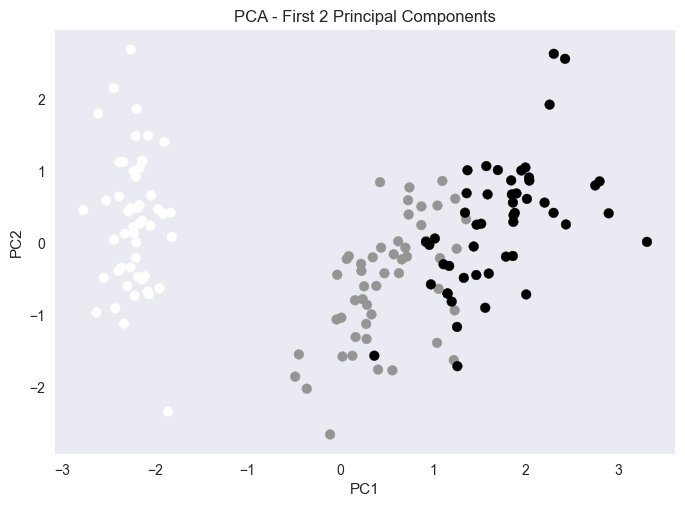

In [23]:
data = load_iris()
X = data.data
X_scaled = StandardScaler().fit_transform(X)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.scatter(X_pca[:, 0], X_pca[:, 1], c=data.target)
plt.title("PCA - First 2 Principal Components")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.grid()
plt.show()

---

### ✅ Exercise
1. Use PCA on the `digits` dataset from `sklearn.datasets` and visualize the first 2 components.
2. Plot the explained variance ratio using `pca.explained_variance_ratio_`.

---

<details>
<summary>🔍 Click here to reveal the solution</summary>

```python
from sklearn.datasets import load_digits

data = load_digits()
X = data.data
X_scaled = StandardScaler().fit_transform(X)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.scatter(X_pca[:, 0], X_pca[:, 1], c=data.target, cmap='viridis')
plt.title("Digits PCA")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.colorbar(); plt.grid(); plt.show()

print("Explained Variance Ratio:", pca.explained_variance_ratio_)
```


---

## 🔹 11. Norms and Distance Metrics

### 📖 Concept

**Norms** measure the size or length of a vector. They are used to quantify how "large" or "far from the origin" a vector is. Different types of norms measure this in different ways.

### 🔢 Common Norms:

1. **L1 Norm (Manhattan norm)**

   $$
   \|x\|_1 = \sum_{i=1}^n |x_i|
   $$

   * Measures distance like a city grid (only horizontal/vertical moves).
   * Promotes sparsity (used in Lasso regression).

2. **L2 Norm (Euclidean norm)**

   $$
   \|x\|_2 = \sqrt{\sum_{i=1}^n x_i^2}
   $$

   * Usual straight-line distance from the origin.
   * Used in Ridge regression and gradient-based optimization.

3. **Infinity Norm (Max norm)**

   $$
   \|x\|_\infty = \max_i |x_i|
   $$

   * Takes the largest absolute value in the vector.

---

### 📏 Distance Metrics:

Distance metrics measure how far apart two vectors are in space. A distance metric is typically derived from a norm.

For example:

* **Euclidean Distance** between vectors $x$ and $y$:

  $$
  d(x, y) = \|x - y\|_2
  $$

* **Manhattan Distance**:

  $$
  d(x, y) = \|x - y\|_1
  $$

These are widely used in clustering (e.g., k-NN, k-means), recommendation systems, and similarity searches.


### 🧪 Code Demonstration

In [24]:
x = np.array([3, 4])
print("L1 norm:", norm(x, 1))
print("L2 norm:", norm(x))
print("Frobenius norm:", norm(A, 'fro'))

L1 norm: 7.0
L2 norm: 5.0
Frobenius norm: 3.872983346207417


---

### ✅ Exercise
1. Create a 10-dimensional vector of random numbers using `np.random.randn(10)` and compare its L1 and L2 norms.

---

<details>
<summary>🔍 Click here to reveal the solution</summary>

```python
x = np.random.randn(10)
print("Vector:", x)
print("L1 norm:", norm(x, 1))
print("L2 norm:", norm(x))
```

---

## 🔹 12. Applications in Machine Learning: Linear Regression
### 📖 Concept


In linear regression, we aim to model the relationship between a dependent variable $y$ and one or more independent variables $X$.

The **normal equation** is a closed-form solution to find the optimal parameters $\beta$ (also called weights or coefficients) that minimize the **Mean Squared Error** in linear regression.

$$
\beta = (X^T X)^{-1} X^T y
$$

Where:

* $X$ is the **design matrix**, where each row is an observation and each column is a feature (with a leading column of 1s for the intercept).
* $y$ is the vector of target values.
* $\beta$ is the vector of model parameters (intercept and coefficients).
* $X^T$ is the transpose of matrix $X$.
* $(X^T X)^{-1}$ is the inverse of $X^T X$, assuming it's invertible.



### 🧪 Code Demonstration

In [25]:
X = np.array([[1, 1], [1, 2], [1, 3]])
y = np.array([1, 2, 3])
X_T = X.T
beta = inv(X_T @ X) @ X_T @ y
print("Coefficients (beta):", beta)

Coefficients (beta): [-1.77635684e-15  1.00000000e+00]


---

### ✅ Exercise
1. Use the `sklearn.datasets.load_diabetes()` dataset. Select one or two features and compute linear regression coefficients using the normal equation.

---

<details>
<summary>🔍 Click here to reveal the solution</summary>

```python
from sklearn.datasets import load_diabetes

data = load_diabetes()
X = data.data[:, :2]  # First two features
y = data.target

X_b = np.c_[np.ones((X.shape[0], 1)), X]  # Add intercept
beta = inv(X_b.T @ X_b) @ X_b.T @ y
print("Coefficients:", beta)
```

---

## 🔹 13. Final Project
Implement PCA from scratch on a real-world dataset (e.g., Wine or Digits dataset) and compare your result with `sklearn`'s PCA.



<details>
<summary>🔍 Click here to reveal the solution</summary>

```python
from sklearn.datasets import load_wine

data = load_wine()
X = data.data
X_scaled = StandardScaler().fit_transform(X)

# PCA from sklearn
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# PCA from scratch
cov_matrix = np.cov(X_scaled.T)
eigvals, eigvecs = eig(cov_matrix)
idx = np.argsort(eigvals)[::-1]
eigvecs = eigvecs[:, idx[:2]]
X_proj = X_scaled @ eigvecs

plt.scatter(X_proj[:, 0], X_proj[:, 1], c=data.target, cmap='viridis')
plt.title("PCA from Scratch")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.colorbar(); plt.grid(); plt.show()
```